In [1]:
import os
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import xml.etree.ElementTree as ET
import contextily as cx

from matplotlib import pyplot as plt



In [2]:
from shapely.geometry import Polygon, box
from pyproj import Transformer, CRS

In [3]:
from LoD2BuildingFunctions import BUILDING_FUNCTIONS_DESCR

# Information

- **Run `~/Daten/AllgemeineDaten/GeoDaten/building-shapes-LoD2/gml_parser_get_bounding_box_per_file` before executing this file**

In [4]:
# Get the bounding boxes
import os
import xml.etree.ElementTree as ET

DATA_PATH = '../data/'

gml_files = sorted([f for f in os.listdir(DATA_PATH) if f.endswith('.gml')])
bbox_data = []

for f_name in gml_files:
    path = os.path.join(DATA_PATH, f_name)
    lower = None
    upper = None
    srs = None
    for event, elem in ET.iterparse(path, events=('start',)):
        if elem.tag.endswith('Envelope'):
            srs = elem.attrib.get('srsName')
            for child in elem:
                if child.tag.endswith('lowerCorner'):
                    lower = child.text.strip()
                elif child.tag.endswith('upperCorner'):
                    upper = child.text.strip()
            break
    
    epsg = 'EPSG:25832'
    bbox_data.append({
        'filename': f_name,
        'lowerCorner': lower,
        'upperCorner': upper,
        'srsName': srs,
        'crs_epsg_code': epsg
    })

bboxes_df = pd.DataFrame(bbox_data)

# Get the EPSG code - check if they are all equal
epsg_codes = bboxes_df.loc[:, "crs_epsg_code"].unique()
assert len(epsg_codes) == 1, "There are mixed CRS EPSG codes!"
crs_data = epsg_codes[0]
print(f"All data of CRS == {crs_data}")

def parse_xy(s: str):
    # strings like "603599.47 5546069.99 331.76" -> keep X,Y; ignore Z
    x_str, y_str, *_ = s.split()
    return float(x_str), float(y_str)

# Extract min/max XY from corner strings
bboxes_df[["minx", "miny"]] = bboxes_df["lowerCorner"].apply(parse_xy).apply(pd.Series)
bboxes_df[["maxx", "maxy"]] = bboxes_df["upperCorner"].apply(parse_xy).apply(pd.Series)

# Build rectangle polygons
geoms = [box(xmin, ymin, xmax, ymax)
         for xmin, ymin, xmax, ymax in zip(bboxes_df.minx, bboxes_df.miny, bboxes_df.maxx, bboxes_df.maxy)]

# Create GeoDataFrame
bboxes_gdf = gpd.GeoDataFrame(bboxes_df.drop(columns=["minx","miny","maxx","maxy"]),
                              geometry=geoms, crs=crs_data)

del epsg_codes
del geoms

bboxes_gdf.head()

All data of CRS == EPSG:25832


,filename,lowerCorner,upperCorner,srsName,crs_epsg_code,geometry
0,562_5510.gml,562354.91 5510672.17 341.83,563135.413 5510798.222 357.27,urn:adv:crs:ETRS89_UTM32*DE_DHHN2016_NH,EPSG:25832,"POLYGON ((563135.413 5510672.17, 563135.413 55..."
1,562_5512.gml,561999.678 5512091.003 247.77,563994.039 5514007.842 354.3,urn:adv:crs:ETRS89_UTM32*DE_DHHN2016_NH,EPSG:25832,"POLYGON ((563994.039 5512091.003, 563994.039 5..."
2,562_5514.gml,562138.21 5513992.33 245.73,564011.043 5516016.52 344.09,urn:adv:crs:ETRS89_UTM32*DE_DHHN2016_NH,EPSG:25832,"POLYGON ((564011.043 5513992.33, 564011.043 55..."
3,562_5516.gml,561987.91 5515991.175 166.81,564026.413 5518014.184 339.15,urn:adv:crs:ETRS89_UTM32*DE_DHHN2016_NH,EPSG:25832,"POLYGON ((564026.413 5515991.175, 564026.413 5..."
4,562_5518.gml,561996.2 5517939.639 166.58,564012.13 5520006.89 260.24,urn:adv:crs:ETRS89_UTM32*DE_DHHN2016_NH,EPSG:25832,"POLYGON ((564012.13 5517939.639, 564012.13 552..."


In [5]:
query_box = box(561000, 5505000, 575000, 5523000)
bboxes_gdf = bboxes_gdf[bboxes_gdf.geometry.intersects(query_box)]


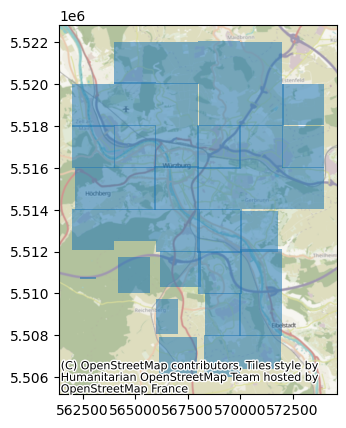

In [6]:
# Optional: Plotting of all available areas
if True:
    fig, ax = plt.subplots()
    bboxes_gdf.plot(ax=ax, alpha=0.55)
    cx.add_basemap(ax=ax, crs=crs_data)

In [7]:
# Check for this notebook: Is the CRS in meters? Otherwise, area calculation will fail

try:
    crs_info = CRS.from_user_input(crs_data)
except Exception:
    raise ValueError(f"Invalid CRS input: {crs_data!r}")

unit_name = crs_info.axis_info[0].unit_name.lower()
assert "metre" in unit_name or "meter" in unit_name, "CRS not in meteres! Area calculation will fail!"

# Information zu CityGML-Dateien (vom Landesamt für Vermessung, Bayern)

General structure:

- `<CityModel>`
    - `<gml:name>` -> File name
    - `<gml:boundedBy>` -> considered area
    - `<cityObjectMember> (multiple)` -> A single entry
        - `<bldg:Building gml:id="DEBY_LOD2_nnnnnnnnn">` -> A building with an ID `DEBY_LOD2_nnnnnnnnn`
            - `<gen:stringAttribute name='...'> (multiple)` -> Different attributes like `HoeheDach`, `HoeheGrund`, ...
            - `<bldg:function>`
            - `<bldg:roofType>`
            - `<bldg>address>`
                - `<Address><xalAddress><xAL:addressDetails>`
                    - `<xAL:Country><xAL:Locality Type="Town">`
                        - `<xAL:LocalityName> Haßfurt/Theres </xAL:LocalityName>`
                        - `<xAL:Thoroughfare Type="Street">`
                            - `<xAL:ThoroughfareName> Alice-von-Swaine-Straße 27 </xAL:ThoroughfareName>`
            - `<bldg:boundedBy> (multiple)`
                - `<bldg:RoofSurface>`, or
                - `<bldg:WallSurface>`, or
                - `<bldg:GroundSurface>`

- An instance of `bldg:RoofSurface` has these members:
    - `<gen:stringAttribute name="...">` -> Attributes `Dachneigung`, `Dachorientierung`, `Flaeche`

- An instance of `bldg:WallSurface` or `bldg:GroundSurface` has these members:
    - `<gen:stringAttribute name="...">` -> Attribute `Flaeche`

- Both have this member sub-structure:
    - `<gml:MultiSurface srsDimension="3">`
        - `<gml:surfaceMember>`
            - `<gml:Polygon>`
                - `<gml:exterior>`
                    - `<gml:LinearRing>`
                        - `<gml:posList> Liste an Koordinaten </gml:posList>`

In [8]:
DATA_PATH = '../data/'

GML_PREFIX  = '{http://www.opengis.net/gml}'
GEN_PREFIX  = '{http://www.opengis.net/citygml/generics/1.0}'
BLDG_PREFIX = '{http://www.opengis.net/citygml/building/1.0}'
XAL_PREFIX  = '{urn:oasis:names:tc:ciq:xsdschema:xAL:2.0}'


# Main code

## Load address data from previous notebook

In [9]:
import os
address_csv = "processing_output/geodata_address_data.csv"
if os.path.exists(address_csv):
    address_df = pd.read_csv(address_csv).set_index("CityGML_ID")
else:
    # Fallback to empty dataframe if file does not exist locally
    address_df = pd.DataFrame(columns=["CityGML_ID", "City", "Street"]).set_index("CityGML_ID")


## Definition of helper functions

In [10]:
def parse_coords_string(s: str) -> np.ndarray:
    """Parse 'x y z x y z ...' into an (N,3) float array."""
    vals = list(map(float, s.split()))
    pts = np.array(vals, dtype=float).reshape(-1, 3)
    # drop duplicate last point if already closed
    if len(pts) > 1 and np.allclose(pts[0], pts[-1]):
        pts = pts[:-1]
    return pts

def poly_area_3d_planar(coords_str: str) -> float:
    """
    3D area of a (nearly) planar polygon (like a roof shape or a wall) given as 'x y z x y z ...'.
    Uses plan-view area / cos(tilt). Units: same as input (e.g., m²).
    """
    P = parse_coords_string(coords_str) # output: (N,3)
    if P.shape[0] < 3:
        return 0.0

    # 1) Plan-view (XY) area (Shapely ignores Z)
    area_xy = Polygon(P[:, :2]).area # m² in EPSG:25832

    # 2) Best-fit plane normal via SVD (stable and tiny)
    #    (subtract centroid, get right-singular vectors; normal is smallest singular vector)
    C = P.mean(axis=0)
    U, S, Vt = np.linalg.svd(P - C, full_matrices=False)
    n = Vt[-1] # plane normal (unit)

    # 3) tilt wrt horizontal (Z axis). cos(tilt) = |n·k|
    cos_tilt = abs(n[2])
    if cos_tilt == 0:
        # vertical plane: projected XY area is zero; fallback to 0 (or handle differently)
        return 0.0

    # 4) 3D area = plan area / cos(tilt)
    return float(area_xy / cos_tilt)

## Code for Building Volume Calculation

In [11]:
import trimesh
from earcut import earcut

In [12]:
def find_best_orthogonal_projection_plane(points:np.array):
    """
    Finds the best orthogonal projection plane (XY, YZ, or XZ) for a set 
    of 3D points by using SVD to identify the axis of least variance.

    Args:
        points (np.ndarray): A (N, 3) array of 3D points. MUST be centered!

    Returns:
        tuple: (indices_to_keep, plane_name)
    """

    # 2. Perform SVD on the centered data matrix
    # The points is N x 3. U is N x N, s is min(N, 3) x 1, Vh is 3 x 3
    # Vh is the V transpose in the formula A = U * S * V^T
    U, s, Vh = np.linalg.svd(points)
    
    # 3. Identify the Least Principal Axis
    # The singular values 's' are sorted in descending order.
    # The corresponding vectors in Vh (rows) are the principal components.
    # The last row of Vh corresponds to the smallest singular value, 
    # which is the axis of least variance.
    least_principal_axis = Vh[-1, :]
    
    # 4. Find the Closest Orthogonal Plane
    # Determine which coordinate axis (X, Y, or Z) is most aligned 
    # with the least principal axis by finding the maximum absolute component.
    # The axis most aligned with the least variance is the one to remove.
    
    # Indices: 0=X, 1=Y, 2=Z
    axis_to_remove_index = np.argmax(np.abs(least_principal_axis))
    
    # Determine the plane and the indices of the columns to keep
    if axis_to_remove_index == 0:
        # X-axis is the axis of least variance -> Project onto YZ plane
        indices_to_keep = [1, 2]
        plane_name = "YZ-plane (removing X-axis)"
    elif axis_to_remove_index == 1:
        # Y-axis is the axis of least variance -> Project onto XZ plane
        indices_to_keep = [0, 2]
        plane_name = "XZ-plane (removing Y-axis)"
    else: # axis_to_remove_index == 2
        # Z-axis is the axis of least variance -> Project onto XY plane
        indices_to_keep = [0, 1]
        plane_name = "XY-plane (removing Z-axis)"
        
    return indices_to_keep, plane_name

def calculate_building_volume_from_LoD2_data(building_data:dict):
    list_of_vertices = None
    list_of_triangel_vertices = None
    vertices_idx_offset = 0
    for surface_name in ["CoordsGroundSurfaces", "CoordsWallSurfaces", "CoordsRoofSurfaces"]:
        for surface_str in building_data[surface_name]:
            v = parse_coords_string(surface_str)
            # get list of vertices
            if list_of_vertices is None:
                list_of_vertices = v
                vertices_idx_offset = 0
            else:
                vertices_idx_offset = list_of_vertices.shape[0]
                list_of_vertices = np.vstack([list_of_vertices, v])
            # get list of triangels
            # 1. Center the Data
            linear_shift = np.mean(v, axis=0)
            # 1. Shift the data to 0.0
            #linear_shift = np.min(v, axis=0)
            centered_points = v - linear_shift
            # 2. find pest optimal 2d-plane
            # 2a. Find the best plane
            indices_to_keep, _ = find_best_orthogonal_projection_plane(centered_points)
            # 2b. Perform the projection
            ##### projected_points = centered_points[:, indices_to_keep]
            projected_points = v[:, indices_to_keep]
            # 3. apply earcut algorithm
            flat_points = [coord for xy in projected_points for coord in xy]
            vertex_ids = earcut.earcut(flat_points)
            # 3. Finally, the VERTEX_IDS must be converted to the acual IDs (offsetted)
            vertex_ids_abs = np.array(vertex_ids, dtype=int) + vertices_idx_offset
            # 3b. split vertex_ids_abs after 3 in a new column
            vertex_ids_abs = np.reshape(vertex_ids_abs, ((-1,3)))
            #
            if list_of_triangel_vertices is None:
                list_of_triangel_vertices = vertex_ids_abs
            else:
                list_of_triangel_vertices = np.vstack([list_of_triangel_vertices, vertex_ids_abs])
    
    # linearily move all points
    moving_vec = list_of_vertices.min(axis=0)
    list_of_vertices = list_of_vertices - moving_vec
    
    mesh = trimesh.Trimesh(vertices= list_of_vertices,
                           faces   = list_of_triangel_vertices,
                           process = True, # merge duplicated vertices
                          )
    if not mesh.is_watertight:
        print("Warning: Building not waterthight!")

    return mesh.is_watertight, mesh.volume, mesh

## Main loop for extracting information on buildings from GeoData

In [13]:
zip_mapping = {
    "Altstadt": 97070,
    "Sanderau": 97072,
    "Frauenland": 97074,
    "Grombühl": 97076,
    "Zellerau": 97078,
    "Lengfeld": 97080,
    "Rottenbauer": 97082,
    "Heidingsfeld": 97084
}

def zip_code_mapping(city_name):
    if not isinstance(city_name, str):
        return 0
    city_name = city_name.strip()
    
    # Check if it's already a ZIP code
    try:
        val = int(city_name)
        if val in zip_mapping.values():
            return val
    except ValueError:
        pass
        
    for name, zip_val in zip_mapping.items():
        if name.lower() == city_name.lower():
            return zip_val
    return 0


In [14]:
cityGML_objects = []
cityGML_obj_surfaces = {}

# Coordinate transformer: EPSG:25832 → EPSG:4326
transformer = Transformer.from_crs("EPSG:25832", "EPSG:4326", always_xy=True)

list_of_required_files = bboxes_gdf.loc[:, "filename"].to_list()
list_of_found_cityGML_IDs = []

all_files = os.listdir(DATA_PATH)
for i, f_name in enumerate(list_of_required_files):
    # skip file, if not required
    if f_name not in all_files:
        print(f"File {f_name} not existing!")
        continue
    
    print(f"Parsing file {f_name} ({i} of {len(list_of_required_files)})")
    tree = ET.parse( os.path.join(DATA_PATH, f_name) )
    tree_root = tree.getroot()
    
    for e in tree_root:
        # The default values
        address_city   = "Unknown"
        address_street = "Unknown"
        address_data_source = "na"
        bFunc  = "Unknown"
        bRoofT = "Unknown"
        surfaces_this_obj = {
            "CoordsGroundSurfaces": [],
            "CoordsWallSurfaces":   [],
            "CoordsRoofSurfaces":   [],
            "InfosRoofSurfaces":    [],
        }
        surface_added = False
        avg_lon,   avg_lat   = -1, -1
        avg_x_utm, avg_y_utm = -1, -1
        # select only the individual units
        if e.tag.endswith('cityObjectMember'):
            if len(e) != 1:
                print("There is a cityObjectMember with more or less than one entity!")
                continue
            bObj  = e[0]
            bID   = bObj.attrib[f"{GML_PREFIX}id"]
            bVolume_m3 = -1.0
            # Skip this building if it is already found in another data source (probably due to overlaps int eh areas of the files)
            if bID in list_of_found_cityGML_IDs:
                continue
            # Get building details
            x = bObj.find(f"{BLDG_PREFIX}function")
            if not x is None:
                bFunc = x.text
            x = bObj.find(f"{BLDG_PREFIX}roofType")
            if not x is None:
                bRoofT = x.text
            #
            # Address data
            addr1 = bObj.findall(f".//{XAL_PREFIX}LocalityName")
            addr2 = bObj.findall(f".//{XAL_PREFIX}ThoroughfareName")
            #addr1 = x.findall("LocalityName")
            #addr2 = x.findall("ThoroughfareName")
            if len(addr1) >= 1:
                address_city   = addr1[0].text
                address_data_source = "CityGML"
            if len(addr2) >= 1:
                address_street = addr2[0].text
                address_data_source = "CityGML"
            #
            # Extract geo-data
            sum_of_groundsurface_area_m2 = 0.0
            sum_of_wallsurface_area_m2   = 0.0
            max_wall_height = 0.0
            for bbound_all in bObj.findall(f"{BLDG_PREFIX}boundedBy"):
                for surface_type in ["GroundSurface", "WallSurface", "RoofSurface"]:
                    for bbound_detail in bbound_all.findall(f"{BLDG_PREFIX}{surface_type}"):
                        for x in bbound_detail.findall(f".//{GML_PREFIX}posList"):
                            surfaces_this_obj[f"Coords{surface_type}s"].append( x.text )
                            surface_added = True
                            if surface_type == "RoofSurface":
                                this_ori   = -1
                                this_pitch = -1
                                this_area  = -1.0
                                for attr in bbound_all.findall(f".//{GEN_PREFIX}stringAttribute"):
                                    if 'name' in attr.attrib.keys() and attr.attrib['name'] == 'Dachneigung':
                                        this_pitch = float(attr[0].text)
                                    if 'name' in attr.attrib.keys() and attr.attrib['name'] == 'Dachorientierung':
                                        this_ori   = float(attr[0].text)
                                    if 'name' in attr.attrib.keys() and attr.attrib['name'] == 'Flaeche':
                                        this_area  = float(attr[0].text)
                                surfaces_this_obj["InfosRoofSurfaces"].append({
                                    "Orientation":    this_ori,
                                    "Pitch":          this_pitch,
                                    "Area data [m2]": this_area,
                                    "Area calc [m2]": poly_area_3d_planar( x.text ),
                                })
                            elif surface_type == "GroundSurface":
                                for attr in bbound_all.findall(f".//{GEN_PREFIX}stringAttribute"):
                                    if 'name' in attr.attrib.keys() and attr.attrib['name'] == 'Flaeche':
                                        sum_of_groundsurface_area_m2 += float(attr[0].text)
                            elif surface_type == "WallSurface":
                                for attr in bbound_all.findall(f".//{GEN_PREFIX}stringAttribute"):
                                    if 'name' in attr.attrib.keys() and attr.attrib['name'] == 'Z_MAX':
                                        this_height_m   = float(attr[0].text)
                                        max_wall_height = max(this_height_m, max_wall_height)
                                        sum_of_wallsurface_area_m2 += this_height_m
            #
            if surface_added:
                #
                # Extract centroid if data available
                centroids_latlon = []
                centroids_xy_utm = []
                for coord_string in surfaces_this_obj['CoordsGroundSurfaces']:
                    coords = list(map(float, coord_string.strip().split()))
                    points3d = [(coords[i], coords[i+1], coords[i+2]) for i in range(0, len(coords), 3)]
                    points2d = [(x, y) for x, y, z in points3d]
                    #
                    if len(points2d) < 3:
                        continue  # skip invalid polygon
                    #
                    polygon = Polygon(points2d)
                    #
                    if not polygon.is_valid:
                        continue  # skip if geometry is invalid
                    # Compute centroid in UTM (EPSG:25832)
                    centroid_utm = polygon.centroid
                    centroids_xy_utm.append((centroid_utm.x, centroid_utm.y))
                    # Transform to lat/lon
                    lon, lat = transformer.transform(centroid_utm.x, centroid_utm.y)
                    centroids_latlon.append((lon, lat))
                if centroids_latlon:
                    avg_lon = sum(lon for lon, lat in centroids_latlon) / len(centroids_latlon)
                    avg_lat = sum(lat for lon, lat in centroids_latlon) / len(centroids_latlon)
                    avg_x_utm = sum(x for x, y in centroids_xy_utm) / len(centroids_xy_utm)
                    avg_y_utm = sum(y for x, y in centroids_xy_utm) / len(centroids_xy_utm)
                #
                # Compute building volume
                volume_valid, volume_m3, _ = calculate_building_volume_from_LoD2_data(surfaces_this_obj)
                if volume_valid:
                    bVolume_m3 = volume_m3
            #
            # Fill missing values (if possible)
            if address_city == "Unknown" and address_street == "Unknown":
                if bID in address_df.index:
                    row = address_df.loc[ bID ]
                    address_data_source = "shp file 2022"
                    address_city   = row["City"]
                    address_street = row["Street"]
            #
            # append to data frame
            zip_code = zip_code_mapping(address_city)
            list_of_found_cityGML_IDs.append( bID )
            cityGML_objects.append({
                "CityGML_ID": bID,
                "City": address_city,
                "Street": address_street,
                "ZIP": zip_code,
                "Address data source": address_data_source,
                "Function": bFunc,
                "Roof type": bRoofT,
                "Ground surface from data [m2]": sum_of_groundsurface_area_m2,
                "Wall surface from data [m2]": sum_of_wallsurface_area_m2,
                "Max wall height from data [m]": max_wall_height,
                "Building volume calculated [m2]": bVolume_m3,
                "Centroid Latitude": avg_lat,
                "Centroid Longitude": avg_lon,
                "Centroid x UTM": avg_x_utm,
                "Centroid y UTM": avg_y_utm,
                "filename": f_name,
            })
            if surface_added:
                cityGML_obj_surfaces[bID] = surfaces_this_obj

del all_files
del list_of_required_files

cityGML_objects = pd.DataFrame(cityGML_objects).reset_index(drop=True)
cityGML_objects.index.name = "Building number"

Parsing file 562_5510.gml (0 of 38)
Parsing file 562_5512.gml (1 of 38)
Parsing file 562_5514.gml (2 of 38)
Parsing file 562_5516.gml (3 of 38)
Parsing file 562_5518.gml (4 of 38)
Parsing file 564_5510.gml (5 of 38)
Parsing file 564_5512.gml (6 of 38)
Parsing file 564_5514.gml (7 of 38)
Parsing file 564_5516.gml (8 of 38)
Parsing file 564_5518.gml (9 of 38)
Parsing file 564_5520.gml (10 of 38)
Parsing file 566_5506.gml (11 of 38)
Parsing file 566_5508.gml (12 of 38)
Parsing file 566_5510.gml (13 of 38)
Parsing file 566_5512.gml (14 of 38)
Parsing file 566_5514.gml (15 of 38)
Parsing file 566_5516.gml (16 of 38)
Parsing file 566_5518.gml (17 of 38)
Parsing file 566_5520.gml (18 of 38)
Parsing file 568_5506.gml (19 of 38)
Parsing file 568_5508.gml (20 of 38)
Parsing file 568_5510.gml (21 of 38)
Parsing file 568_5512.gml (22 of 38)
Parsing file 568_5514.gml (23 of 38)
Parsing file 568_5516.gml (24 of 38)
Parsing file 568_5518.gml (25 of 38)
Parsing file 568_5520.gml (26 of 38)
Parsing fil

In [15]:
roof_records = []
for b_id, surfaces in cityGML_obj_surfaces.items():
    coords_list = surfaces.get("CoordsRoofSurfaces", [])
    infos_list = surfaces.get("InfosRoofSurfaces", [])
    for idx, (coords_str, info) in enumerate(zip(coords_list, infos_list)):
        roof_records.append({
            "Building_ID": b_id,
            "Roof_Index": idx,
            "roof_coords": coords_str,
            "pitch": info.get("Pitch"),
            "orientation": info.get("Orientation")
        })
roof_df = pd.DataFrame(roof_records)


In [16]:
cityGML_objects.head()

,CityGML_ID,City,Street,ZIP,Address data source,Function,Roof type,Ground surface from data [m2],Wall surface from data [m2],Max wall height from data [m],Building volume calculated [m2],Centroid Latitude,Centroid Longitude,Centroid x UTM,Centroid y UTM,filename
Building number,,,,,,,,,,,,,,,,
0,DEBY_LOD2_106806040,Unknown,Unknown,0,na,31001_2523,1000,8.223,14.000,3.500,36.977675,49.745323,9.865664,562366.356719,5.510675e+06,562_5510.gml
1,DEBY_LOD2_106806042,Unknown,Unknown,0,na,31001_2523,1000,3.880,11.200,2.800,13.835080,49.745310,9.865521,562356.076362,5.510673e+06,562_5510.gml
2,DEBY_LOD2_108541435,Unknown,Unknown,0,na,51009_1700,1000,53.663,25.914,4.319,8576.369121,49.746275,9.875531,563075.924924,5.510789e+06,562_5510.gml
3,DEBY_LOD2_108542025,Unknown,Unknown,0,na,51009_1700,1000,66.393,47.522,4.888,-2146.858470,49.745675,9.868378,562561.387291,5.510716e+06,562_5510.gml
4,DEBY_LOD2_108542028,Unknown,Unknown,0,na,51009_1700,1000,51.375,33.450,6.497,-2625.695849,49.746063,9.867858,562523.464606,5.510759e+06,562_5510.gml


# Output

In [17]:
# Export handled in final cell


In [19]:
import os
import json

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(r"E:\EnergyPraktikum_main")

out_dir = r"E:\EnergyPraktikum_main\outputs"

# Export standalone roof data
roof_df.to_csv(os.path.join(out_dir, "wuerzburg_roof_details.csv"), index=False)
roof_dict = roof_df.to_dict(orient="records")
with open(os.path.join(out_dir, "wuerzburg_roof_details.json"), "w", encoding="utf-8") as f:
    json.dump(roof_dict, f)


In [20]:
cityGML_objects.to_csv("outputs/cityGML_objects.csv", index=False)
with open("outputs/cityGML_obj_surfaces.json", "w") as f:
    json.dump(cityGML_obj_surfaces, f)


# Exemplary building analysis

In [21]:
ID_EXAMPLE_1 = 'DEBY_LOD2_506720' # Ein Wohngebäude, das ein Volumen von ca. 315m^3 hat
ID_EXAMPLE_2 = 'DEBY_LOD2_107866770' # Ein großes Gebäude mit komplexer Struktur


In [22]:
cityGML_obj_surfaces[ID_EXAMPLE_2]


{'CoordsGroundSurfaces': ['566235.271 5515784.054 220.98 566235.207 5515783.997 220.98 566214.192 5515770.899 220.98 566183.256 5515753.258 220.98 566182.938 5515753.318 220.98 566182.269 5515754.144 220.98 566182.249 5515754.172 220.98 566170.165 5515774.219 220.98 566114.703 5515766.722 220.98 566117.594 5515742.709 220.98 566117.372 5515742.43 220.98 566019.581 5515732.27 220.98 566019.305 5515732.524 220.98 566019.554 5515744.229 220.98 565981.309 5515747.764 220.98 565943.299 5515749.912 220.98 565946.704 5515734.296 220.98 565955.631 5515693.103 220.98 565969.192 5515689.964 220.98 565969.239 5515689.948 220.98 565970.636 5515689.313 220.98 565970.776 5515689.026 220.98 565962.902 5515656.387 220.98 565962.595 5515656.204 220.98 565950.182 5515659.464 220.98 565919.255 5515619.589 220.98 565909.799 5515606.487 220.98 565909.775 5515606.458 220.98 565901.072 5515597.53 220.98 565900.714 5515597.88 220.98 565909.404 5515606.794 220.98 565918.852 5515619.885 220.98 565949.888 551565

In [23]:
cityGML_objects.query(f"CityGML_ID == '{ID_EXAMPLE_2}'")

,CityGML_ID,City,Street,ZIP,Address data source,Function,Roof type,Ground surface from data [m2],Wall surface from data [m2],Max wall height from data [m],Building volume calculated [m2],Centroid Latitude,Centroid Longitude,Centroid x UTM,Centroid y UTM,filename
Building number,,,,,,,,,,,,,,,,
30053,DEBY_LOD2_107866770,Unknown,Unknown,0,na,51007_1500,1000,354.816,1947.431,33.497,2.594456e+06,49.790574,9.918214,566090.64647,5.515751e+06,566_5514.gml


In [24]:
cityGML_objects.loc[ cityGML_objects.loc[:, "CityGML_ID"] == ID_EXAMPLE_1 ]

,CityGML_ID,City,Street,ZIP,Address data source,Function,Roof type,Ground surface from data [m2],Wall surface from data [m2],Max wall height from data [m],Building volume calculated [m2],Centroid Latitude,Centroid Longitude,Centroid x UTM,Centroid y UTM,filename
Building number,,,,,,,,,,,,,,,,
25,DEBY_LOD2_506720,Höchberg,Einsteinstraße 3,0,CityGML,31001_1000,3100,170.392,115.908,11.019,315.672816,49.772432,9.87073,562696.345793,5.513693e+06,562_5512.gml


In [25]:
valid, volume_m3, mesh = calculate_building_volume_from_LoD2_data( cityGML_obj_surfaces[ID_EXAMPLE_1] )
print("The volume is ", volume_m3)

The volume is  315.6728156287279


In [26]:
#mesh.show()